# VisionCheckout prototype — DINOv2 evaluation and fine-tuning (Google Colab)

This notebook:
1. Downloads the **Grocery Store Dataset** (Klasson et al.), which covers 17 of the 20 prototype items (broccoli, celery and corn are missing).
2. **Baseline:** evaluates DINOv2 ViT-S/14 *without training*: enroll items from training photos, classify test photos, and reject non-items.
3. **Fine-tunes** the last DINOv2 blocks plus a projection head with ArcFace + supervised contrastive loss.
4. **Re-evaluates** with the same protocol and compares the two.
5. Saves the fine-tuned weights to Google Drive.

**Before running:** *Runtime → Change runtime type → GPU* (a T4 is enough). Then *Runtime → Run all*. Total time is about 15–25 minutes on a T4.

Scores on this dataset (cluttered store photos, one image per decision, no frame voting) will be lower than the prototype's on a plain mat. Use them to compare models and find look-alike problems.

In [1]:
#@title 1. Setup
!nvidia-smi -L || echo "No GPU: Runtime > Change runtime type > GPU"
!pip -q install transformers scikit-learn pandas
import os, csv, json, math, random, time, itertools, copy
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Sampler
import torchvision.transforms as T
from transformers import AutoModel
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__)

GPU 0: Tesla T4 (UUID: GPU-45ba5e48-7a1d-41a2-d025-7300cd61e6f2)
device: cuda | torch 2.14.1+cu130


In [2]:
#@title 2. Configuration
MODEL_NAME   = "facebook/dinov2-small"   #@param ["facebook/dinov2-small", "facebook/dinov2-base"]
ENROLL_SHOTS = 0      #@param {type:"integer"}  # enrollment photos per item for evaluation (0 = all training photos)
PROTOS_K     = 5      #@param {type:"integer"}  # prototypes per item (k-means); 0 = every enrollment photo
TEMPERATURE  = 0.05
TARGET_PRECISION, MAX_UNKNOWN_FAR = 0.99, 0.02

# fine-tuning (DESIGN.md §13.9)
EPOCHS, UNFROZEN_BLOCKS, EMB_DIM = 30, 4, 512
P_ITEMS, K_PER_ITEM = 17, 8          # P×K batch = 136 images
LR_BACKBONE, LR_HEAD, WEIGHT_DECAY, WARMUP_EPOCHS = 1e-5, 3e-4, 0.05, 2
ARC_S, ARC_M, LABEL_SMOOTH, SUPCON_T, SUPCON_W = 30.0, 0.30, 0.1, 0.07, 0.5
PATIENCE, SEED = 5, 0

SAVE_TO_DRIVE = True  #@param {type:"boolean"}
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

In [3]:
#@title 3. Download the Grocery Store Dataset
if not Path("GroceryStoreDataset").exists():
    !git clone -q --depth 1 https://github.com/marcusklasson/GroceryStoreDataset
ROOT = Path("GroceryStoreDataset/dataset")

# dataset fine class -> prototype item; anything else counts as an "unknown" (non-item) object
ITEM_MAP = {
    "Golden-Delicious":"apple","Granny-Smith":"apple","Pink-Lady":"apple","Red-Delicious":"apple","Royal-Gala":"apple",
    "Banana":"banana","Orange":"orange","Kiwi":"kiwi","Pineapple":"pineapple","Pomegranate":"pomegranate",
    "Lemon":"lemon","Lime":"lime","Yellow-Onion":"onion","Carrots":"carrots",
    "Floury-Potato":"potato","Solid-Potato":"potato","Cucumber":"cucumber",
    "Beef-Tomato":"tomato","Regular-Tomato":"tomato","Vine-Tomato":"tomato",
    "Ginger":"ginger","Brown-Cap-Mushroom":"mushroom","Cabbage":"cabbage","Green-Bell-Pepper":"green_bell_pepper"}
MISSING = ["broccoli", "celery", "corn"]

with open(ROOT/"classes.csv") as f:
    r = csv.reader(f); next(r); ID2NAME = {int(x[1]): x[0] for x in r}

def load_split(split):
    rows = []
    for line in (ROOT/f"{split}.txt").read_text().splitlines():
        if line.strip():
            p, fine, _ = [x.strip() for x in line.split(",")]
            rows.append((ROOT/p, ITEM_MAP.get(ID2NAME[int(fine)])))
    return rows

TRAIN, VAL, TEST = (load_split(s) for s in ("train", "val", "test"))
ITEMS = sorted({it for _, it in TRAIN if it}); IDX = {n: i for i, n in enumerate(ITEMS)}
train_known = [r for r in TRAIN if r[1]]
val_known, val_unknown = [r for r in VAL if r[1]], [r for r in VAL if not r[1]]
test_known, test_unknown = [r for r in TEST if r[1]], [r for r in TEST if not r[1]]
print(f"{len(ITEMS)} items (missing from dataset: {', '.join(MISSING)})")
print(f"train {len(train_known)} | val {len(val_known)} known + {len(val_unknown)} unknown | "
      f"test {len(test_known)} known + {len(test_unknown)} unknown")
print(pd.Series([it for _, it in train_known]).value_counts().rename("train images").to_frame().T)

17 items (missing from dataset: broccoli, celery, corn)
train 936 | val 100 known + 196 unknown | test 889 known + 1596 unknown
              apple  tomato  orange  potato  kiwi  banana  carrots  lemon  \
train images    278     127      57      46    46      45       43     42   

              mushroom  onion  lime  cucumber  pineapple  green_bell_pepper  \
train images        39     38    31        28         26                 26   

              pomegranate  cabbage  ginger  
train images           26       19      19  


In [4]:
#@title 4. Model: DINOv2 backbone + optional projection head
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
EVAL_TF = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(), T.Normalize(MEAN, STD)])

class Embedder(nn.Module):
    # use_head=False: frozen baseline, embedding = L2(CLS ++ mean patch) (768-d for ViT-S)
    # use_head=True : fine-tuned, embedding = L2(Linear(CLS ++ mean patch)) (EMB_DIM)
    def __init__(self, name, use_head=False, emb_dim=EMB_DIM):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(name)
        d = 2 * self.backbone.config.hidden_size
        self.use_head = use_head
        self.head = nn.Sequential(nn.Linear(d, emb_dim), nn.BatchNorm1d(emb_dim)) if use_head else nn.Identity()
        self.dim = emb_dim if use_head else d
    def forward(self, x):
        h = self.backbone(pixel_values=x).last_hidden_state
        f = torch.cat([h[:, 0], h[:, 1:].mean(1)], 1)
        return F.normalize(self.head(f).float(), dim=1)

class ImgDS(Dataset):
    def __init__(self, rows, tf, with_label=True):
        self.rows, self.tf, self.wl = rows, tf, with_label
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        p, it = self.rows[i]
        x = self.tf(Image.open(p).convert("RGB"))
        return (x, IDX[it]) if self.wl else x

@torch.inference_mode()
def embed(model, rows, bs=64):
    model.eval(); out = []
    dl = DataLoader(ImgDS(rows, EVAL_TF, with_label=False), batch_size=bs, num_workers=2)
    for x in dl:
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            out.append(model(x.to(DEVICE)).float().cpu())
    return torch.cat(out).numpy()

In [5]:
#@title 5. Evaluation protocol (enroll → classify → accept/reject)
from sklearn.cluster import KMeans

def build_prototypes(E, items, k):
    P, owner = [], []
    for j, it in enumerate(ITEMS):
        X = E[[i for i, y in enumerate(items) if y == it]]
        if k and len(X) > k:
            C = KMeans(k, n_init=10, random_state=SEED).fit(X).cluster_centers_
            X = C / np.linalg.norm(C, axis=1, keepdims=True)
        P.append(X); owner += [j] * len(X)
    return np.concatenate(P).astype(np.float32), np.array(owner)

def item_scores(Q, P, owner):
    S = Q @ P.T
    return np.stack([S[:, owner == j].max(1) for j in range(len(ITEMS))], 1)

def accept(S, min_cos, margin, conf):
    s = np.sort(S, 1); z = (S - S.max(1, keepdims=True)) / TEMPERATURE
    c = (np.exp(z) / np.exp(z).sum(1, keepdims=True)).max(1)
    return (c >= conf) & (s[:, -1] >= min_cos) & (s[:, -1] - s[:, -2] >= margin)

def decision_stats(Sk, Su, y, params):
    ak, au = accept(Sk, *params), accept(Su, *params)
    correct = (ak & (Sk.argmax(1) == y)).sum(); n = ak.sum() + au.sum()
    return dict(precision=correct / n if n else 1.0, recall=correct / len(y), unknown_far=au.mean())

def sweep(Sk, Su, y):
    rows = []
    for p in itertools.product(np.round(np.arange(0.20, 0.91, 0.025), 3),
                               [0, .02, .04, .06, .08, .10, .12, .15], [0, .5, .6, .7, .8, .9]):
        rows.append(dict(min_cosine=p[0], margin=p[1], conf=p[2], **decision_stats(Sk, Su, y, p)))
    df = pd.DataFrame(rows)
    ok = df[(df.precision >= TARGET_PRECISION) & (df.unknown_far <= MAX_UNKNOWN_FAR)]
    if len(ok): return ok.sort_values("recall").iloc[-1], df
    ok = df[df.precision >= TARGET_PRECISION]
    return (ok.sort_values("recall").iloc[-1] if len(ok) else df.sort_values("precision").iloc[-1]), df

def evaluate(model, name, shots=ENROLL_SHOTS, k=PROTOS_K, tune_on_val=True):
    enroll = train_known
    if shots:
        by = {}
        for r in train_known: by.setdefault(r[1], []).append(r)
        rng = random.Random(SEED)
        enroll = [r for it in ITEMS for r in rng.sample(by[it], min(shots, len(by[it])))]
    t0 = time.time()
    E_en = embed(model, enroll)
    E_tk, E_tu = embed(model, test_known), embed(model, test_unknown)
    E_vk, E_vu = embed(model, val_known), embed(model, val_unknown)
    ms = 1000 * (time.time() - t0) / (len(enroll) + len(test_known) + len(test_unknown) + len(VAL))
    P, owner = build_prototypes(E_en, [r[1] for r in enroll], k)
    y_t = np.array([IDX[r[1]] for r in test_known]); y_v = np.array([IDX[r[1]] for r in val_known])
    S_tk, S_tu = item_scores(E_tk, P, owner), item_scores(E_tu, P, owner)
    S_vk, S_vu = item_scores(E_vk, P, owner), item_scores(E_vu, P, owner)

    rank = np.argsort(-S_tk, 1)
    top1, top3 = (rank[:, 0] == y_t).mean(), (rank[:, :3] == y_t[:, None]).any(1).mean()
    cm = pd.crosstab(pd.Series([ITEMS[i] for i in y_t], name="true"),
                     pd.Series([ITEMS[i] for i in rank[:, 0]], name="pred")).reindex(index=ITEMS, columns=ITEMS, fill_value=0)
    # thresholds: tuned on VAL (honest), applied to TEST
    best, _ = sweep(S_vk, S_vu, y_v) if tune_on_val else sweep(S_tk, S_tu, y_t)
    params = (best.min_cosine, best.margin, best.conf)
    tuned = decision_stats(S_tk, S_tu, y_t, params)
    default = decision_stats(S_tk, S_tu, y_t, (0.55, 0.10, 0.80))
    res = dict(model=name, top1=top1, top3=top3, ms_per_img=ms,
               default_precision=default["precision"], default_recall=default["recall"], default_unknown_far=default["unknown_far"],
               tuned_precision=tuned["precision"], tuned_recall=tuned["recall"], tuned_unknown_far=tuned["unknown_far"],
               min_cosine=params[0], margin=params[1], conf=params[2])
    per_item = pd.Series(np.diag(cm.values) / cm.values.sum(1), index=ITEMS, name=name)
    pairs = [(cm.loc[a, b], a, b) for a in ITEMS for b in ITEMS if a != b and cm.loc[a, b]]
    print(f"\n=== {name} ===  top-1 {top1:.1%} | top-3 {top3:.1%} | {ms:.1f} ms/img")
    print(f"default thresholds (0.55/0.10/0.80): precision {default['precision']:.1%}, recall {default['recall']:.1%}, unknown FAR {default['unknown_far']:.1%}")
    print(f"tuned on val {params}: precision {tuned['precision']:.1%}, recall {tuned['recall']:.1%}, unknown FAR {tuned['unknown_far']:.1%}")
    print("top confusions (true → pred):", ", ".join(f"{a}→{b} ({c})" for c, a, b in sorted(pairs, reverse=True)[:8]))
    return res, per_item, cm

## Baseline: DINOv2 with no training

In [6]:
#@title 6. Baseline evaluation
base_model = Embedder(MODEL_NAME, use_head=False).to(DEVICE)
res_base, item_base, cm_base = evaluate(base_model, "DINOv2 frozen")
res_base20, _, _ = evaluate(base_model, "DINOv2 frozen, 20-shot enroll", shots=20)

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]


=== DINOv2 frozen ===  top-1 94.3% | top-3 98.9% | 4.7 ms/img
default thresholds (0.55/0.10/0.80): precision 81.1%, recall 72.3%, unknown FAR 9.2%
tuned on val (np.float64(0.725), np.float64(0.08), np.float64(0.8)): precision 80.7%, recall 75.4%, unknown FAR 9.8%
top confusions (true → pred): lemon→lime (12), lemon→orange (11), pomegranate→apple (9), kiwi→pineapple (3), ginger→kiwi (2), cucumber→tomato (2), orange→lime (1), orange→lemon (1)

=== DINOv2 frozen, 20-shot enroll ===  top-1 94.3% | top-3 99.1% | 4.1 ms/img
default thresholds (0.55/0.10/0.80): precision 80.4%, recall 67.0%, unknown FAR 8.9%
tuned on val (np.float64(0.775), np.float64(0.06), np.float64(0.8)): precision 81.8%, recall 67.6%, unknown FAR 8.3%
top confusions (true → pred): lemon→orange (12), lemon→lime (10), orange→lemon (4), ginger→carrots (3), cucumber→tomato (3), pomegranate→apple (2), orange→lime (2), lime→lemon (2)


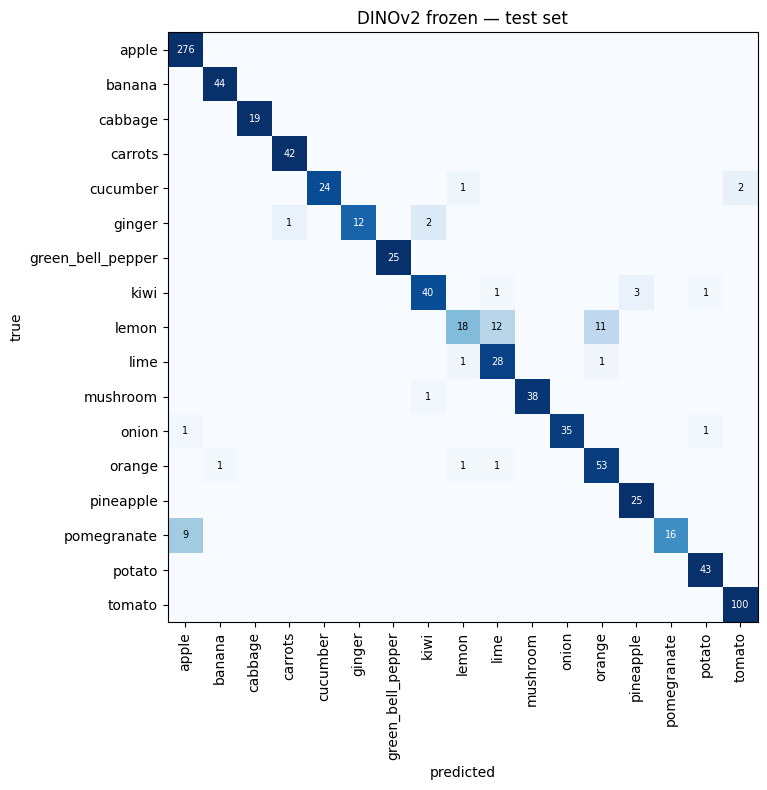

In [7]:
#@title 7. Baseline confusion matrix
import matplotlib.pyplot as plt
def plot_cm(cm, title):
    m = cm.values / cm.values.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(9, 8)); ax.imshow(m, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(ITEMS)), ITEMS, rotation=90); ax.set_yticks(range(len(ITEMS)), ITEMS)
    for i in range(len(ITEMS)):
        for j in range(len(ITEMS)):
            if cm.values[i, j]: ax.text(j, i, cm.values[i, j], ha="center", va="center", fontsize=7,
                                        color="white" if m[i, j] > .5 else "black")
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title); plt.tight_layout(); plt.show()
plot_cm(cm_base, "DINOv2 frozen — test set")

## Fine-tuning
Unfreezes the last `UNFROZEN_BLOCKS` transformer blocks and trains them with a 512-d projection head.
- **Loss:** ArcFace (s=30, margin warm-up 0→0.30 over the first 5 epochs, label smoothing 0.1) + 0.5 × supervised contrastive loss (τ=0.07).
- **Batches:** P×K (8 photos of each of the 17 items).
- **Augmentation:** keeps hue jitter tiny (0.02), because colour separates lemon from lime.
- **Data:** only the training split of the 17 items. Non-items and the test split are never used for training.
- **Early stopping:** on validation accuracy.

In [8]:
#@title 8. Training components
TRAIN_TF = T.Compose([
    T.RandomResizedCrop(224, scale=(0.5, 1.0), ratio=(0.75, 1.33)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(180),
    T.ColorJitter(0.3, 0.3, 0.2, 0.02), T.RandomApply([T.GaussianBlur(5)], p=0.1),
    T.ToTensor(), T.Normalize(MEAN, STD), T.RandomErasing(p=0.2, scale=(0.02, 0.15))])

class PKSampler(Sampler):
    def __init__(self, labels, P, K, n_batches):
        self.by = {}; [self.by.setdefault(l, []).append(i) for i, l in enumerate(labels)]
        self.P, self.K, self.n = min(P, len(self.by)), K, n_batches
    def __len__(self): return self.n
    def __iter__(self):
        for _ in range(self.n):
            cls = random.sample(list(self.by), self.P)
            yield [i for c in cls for i in (random.sample(self.by[c], self.K) if len(self.by[c]) >= self.K
                                            else random.choices(self.by[c], k=self.K))]

class ArcFace(nn.Module):
    def __init__(self, dim, n, s=ARC_S, m=ARC_M):
        super().__init__(); self.W = nn.Parameter(torch.randn(n, dim) * 0.01); self.s, self.m = s, m
    def forward(self, e, y, m=None):
        m = self.m if m is None else m
        cos = (e @ F.normalize(self.W, dim=1).T).clamp(-1 + 1e-7, 1 - 1e-7)
        target = torch.cos(torch.acos(cos.gather(1, y[:, None])) + m)
        logits = cos.scatter(1, y[:, None], target) * self.s
        return F.cross_entropy(logits, y, label_smoothing=LABEL_SMOOTH)

def supcon(e, y, t=SUPCON_T):
    sim = e @ e.T / t
    self_mask = torch.eye(len(y), device=e.device, dtype=torch.bool)
    pos = (y[:, None] == y[None]) & ~self_mask
    sim = sim.masked_fill(self_mask, -1e9)
    logp = sim - torch.logsumexp(sim, 1, keepdim=True)
    return -(logp * pos).sum(1).div(pos.sum(1).clamp(min=1)).mean()

@torch.inference_mode()
def val_top1(model):
    P, owner = build_prototypes(embed(model, train_known), [r[1] for r in train_known], PROTOS_K)
    y = np.array([IDX[r[1]] for r in val_known])
    return (item_scores(embed(model, val_known), P, owner).argmax(1) == y).mean()

In [9]:
#@title 9. Fine-tune
model = Embedder(MODEL_NAME, use_head=True).to(DEVICE)
for p in model.backbone.parameters(): p.requires_grad = False
n_blocks = len(model.backbone.encoder.layer)
for blk in model.backbone.encoder.layer[n_blocks - UNFROZEN_BLOCKS:]:
    for p in blk.parameters(): p.requires_grad = True
for p in model.backbone.layernorm.parameters(): p.requires_grad = True
arc = ArcFace(EMB_DIM, len(ITEMS)).to(DEVICE)

labels = [IDX[r[1]] for r in train_known]
steps_per_epoch = max(1, len(train_known) // (P_ITEMS * K_PER_ITEM))
dl = DataLoader(ImgDS(train_known, TRAIN_TF), num_workers=2, pin_memory=True,
                batch_sampler=PKSampler(labels, P_ITEMS, K_PER_ITEM, steps_per_epoch))
opt = torch.optim.AdamW([
    {"params": [p for p in model.backbone.parameters() if p.requires_grad], "lr": LR_BACKBONE},
    {"params": list(model.head.parameters()) + list(arc.parameters()), "lr": LR_HEAD}], weight_decay=WEIGHT_DECAY)
total, warm = EPOCHS * steps_per_epoch, WARMUP_EPOCHS * steps_per_epoch
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm
                                          else 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
scaler = torch.cuda.amp.GradScaler(enabled=DEVICE == "cuda")

best_acc, best_state, bad, history = -1, None, 0, []
for ep in range(EPOCHS):
    model.train(); t0, tot = time.time(), 0.0
    margin = ARC_M * min(1.0, (ep + 1) / 5)                       # ArcFace margin warm-up
    for x, y in dl:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            e = model(x)
        loss = arc(e.float(), y, margin) + SUPCON_W * supcon(e.float(), y)
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(list(model.parameters()) + list(arc.parameters()), 1.0)
        scaler.step(opt); scaler.update(); sched.step(); tot += loss.item()
    acc = val_top1(model); history.append((ep + 1, tot / steps_per_epoch, acc))
    print(f"epoch {ep+1:2d} | loss {tot/steps_per_epoch:.3f} | val top-1 {acc:.1%} | {time.time()-t0:.0f}s")
    if acc > best_acc: best_acc, best_state, bad = acc, copy.deepcopy(model.state_dict()), 0
    else:
        bad += 1
        if bad >= PATIENCE: print("early stop"); break
model.load_state_dict(best_state); print(f"best val top-1 {best_acc:.1%}")

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

/tmp/ipykernel_2742/948569795.py:20: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE == "cuda")


epoch  1 | loss 6.275 | val top-1 97.0% | 14s
epoch  2 | loss 3.743 | val top-1 98.0% | 13s
epoch  3 | loss 2.687 | val top-1 100.0% | 12s
epoch  4 | loss 2.430 | val top-1 100.0% | 20s
epoch  5 | loss 2.376 | val top-1 100.0% | 21s
epoch  6 | loss 2.183 | val top-1 100.0% | 19s
epoch  7 | loss 2.102 | val top-1 100.0% | 13s
epoch  8 | loss 2.014 | val top-1 99.0% | 13s
early stop
best val top-1 100.0%


## Fine-tuned evaluation and comparison


=== DINOv2 fine-tuned ===  top-1 97.1% | top-3 99.9% | 4.1 ms/img
default thresholds (0.55/0.10/0.80): precision 70.0%, recall 90.2%, unknown FAR 21.1%
tuned on val (np.float64(0.9), np.float64(0.0), np.float64(0.6)): precision 86.4%, recall 60.0%, unknown FAR 5.1%
top confusions (true → pred): lemon→orange (10), lemon→lime (6), orange→banana (2), cucumber→tomato (2), pomegranate→apple (1), orange→lemon (1), mushroom→cabbage (1), kiwi→ginger (1)

=== DINOv2 fine-tuned, 20-shot enroll ===  top-1 97.2% | top-3 99.7% | 4.4 ms/img
default thresholds (0.55/0.10/0.80): precision 68.9%, recall 91.2%, unknown FAR 22.5%
tuned on val (np.float64(0.9), np.float64(0.1), np.float64(0.0)): precision 87.1%, recall 54.0%, unknown FAR 4.3%
top confusions (true → pred): lemon→orange (9), lemon→lime (5), orange→lemon (2), orange→banana (2), cucumber→tomato (2), mushroom→cabbage (1), lemon→apple (1), kiwi→pineapple (1)


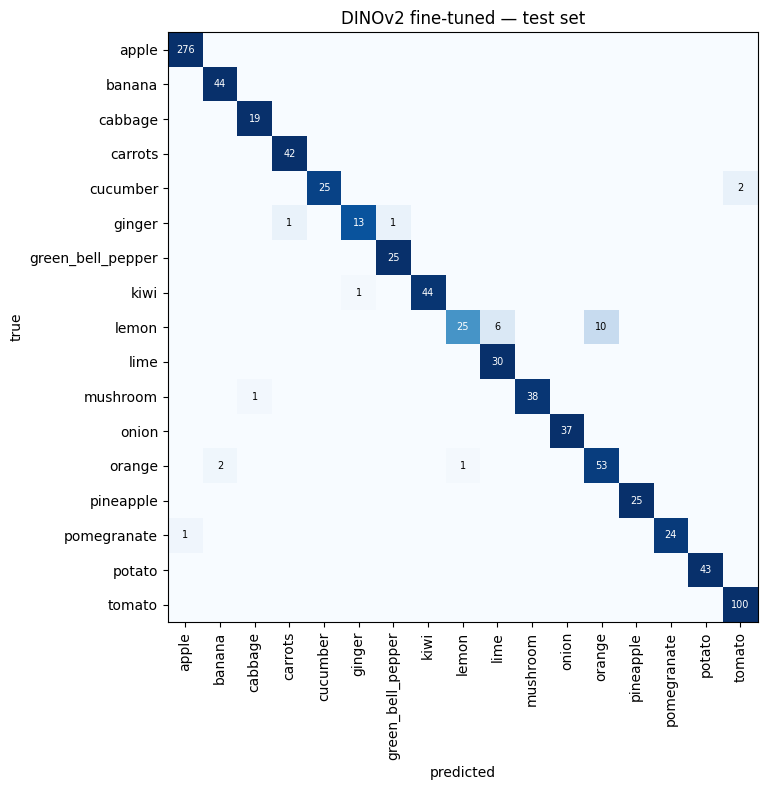

,top1,top3,ms_per_img,default_precision,default_recall,default_unknown_far,tuned_precision,tuned_recall,tuned_unknown_far,min_cosine,margin,conf
model,,,,,,,,,,,,
DINOv2 frozen,94.3%,98.9%,4.7,81.1%,72.3%,9.2%,80.7%,75.4%,9.8%,0.725000,0.080000,0.800000
"DINOv2 frozen, 20-shot enroll",94.3%,99.1%,4.1,80.4%,67.0%,8.9%,81.8%,67.6%,8.3%,0.775000,0.060000,0.800000
DINOv2 fine-tuned,97.1%,99.9%,4.1,70.0%,90.2%,21.1%,86.4%,60.0%,5.1%,0.900000,0.000000,0.600000
"DINOv2 fine-tuned, 20-shot enroll",97.2%,99.7%,4.4,68.9%,91.2%,22.5%,87.1%,54.0%,4.3%,0.900000,0.100000,0.000000


,DINOv2 frozen,DINOv2 fine-tuned
apple,100.0%,100.0%
banana,100.0%,100.0%
cabbage,100.0%,100.0%
carrots,100.0%,100.0%
cucumber,88.9%,92.6%
ginger,80.0%,86.7%
green_bell_pepper,100.0%,100.0%
kiwi,88.9%,97.8%
lemon,43.9%,61.0%
lime,93.3%,100.0%


Prototype targets: top-1 ≥ 95%, precision ≥ 99%, recall ≥ 90%, unknown FAR ≤ 2% (on your own webcam data).


In [10]:
#@title 10. Evaluate fine-tuned model
res_ft, item_ft, cm_ft = evaluate(model, "DINOv2 fine-tuned")
res_ft20, _, _ = evaluate(model, "DINOv2 fine-tuned, 20-shot enroll", shots=20)
plot_cm(cm_ft, "DINOv2 fine-tuned — test set")

summary = pd.DataFrame([res_base, res_base20, res_ft, res_ft20]).set_index("model")
pct = [c for c in summary.columns if c not in ("ms_per_img", "min_cosine", "margin", "conf")]
display(summary.style.format({**{c: "{:.1%}" for c in pct}, "ms_per_img": "{:.1f}"}))
display(pd.concat([item_base, item_ft], axis=1).style.format("{:.1%}"))
print("Prototype targets: top-1 ≥ 95%, precision ≥ 99%, recall ≥ 90%, unknown FAR ≤ 2% (on your own webcam data).")

In [ ]:
#@title 11. Save the fine-tuned model
out = Path("vc_proto_model"); out.mkdir(exist_ok=True)
torch.save({"model_name": MODEL_NAME, "unfrozen_blocks": UNFROZEN_BLOCKS, "emb_dim": EMB_DIM, "items": ITEMS,
            "state_dict": model.state_dict(), "history": history,
            "thresholds": {"min_cosine": float(res_ft["min_cosine"]), "margin": float(res_ft["margin"]),
                           "conf": float(res_ft["conf"]), "temperature": TEMPERATURE}}, out/"proto_embedder.pt")
summary.to_csv(out/"summary.csv"); cm_ft.to_csv(out/"confusion_matrix_finetuned.csv")
if SAVE_TO_DRIVE:
    from google.colab import drive; drive.mount("/content/drive")
    dst = Path("/content/drive/MyDrive/visioncheckout"); dst.mkdir(parents=True, exist_ok=True)
    !cp -r vc_proto_model/* /content/drive/MyDrive/visioncheckout/
    print("saved to Google Drive: MyDrive/visioncheckout/")
else:
    !zip -qr vc_proto_model.zip vc_proto_model
    from google.colab import files; files.download("vc_proto_model.zip")
print("Remember: re-enroll all items with this model before using it in the prototype (DESIGN.md §13.9 step 2).")

## Inference: classify your own images
Run after the cells above. These cells use the **fine-tuned model** if it exists (otherwise the frozen baseline), enroll the 17 items, and then classify:
- **A.** random test photos from the dataset,
- **B.** images you upload,
- **C.** a snapshot from your webcam (Colab asks for camera permission).

Each image gets the top-3 items with similarity and confidence, plus the scan/reject decision from the same rule as the prototype (confidence, minimum similarity, margin). Thresholds come from the evaluation above; you can override them in the next cell.

In [ ]:
#@title 12. Inference setup: pick model, enroll items, set thresholds
INFER_MODEL = model if "model" in globals() else base_model      # fine-tuned if trained, else frozen
_res = res_ft if INFER_MODEL is not base_model and "res_ft" in globals() else res_base
INFER_SHOTS = 20   #@param {type:"integer"}  # enrollment photos per item (0 = all training photos), like the prototype
USE_TUNED_THRESHOLDS = True  #@param {type:"boolean"}
MIN_COS, MARGIN, CONF = ((float(_res["min_cosine"]), float(_res["margin"]), float(_res["conf"]))
                         if USE_TUNED_THRESHOLDS else (0.55, 0.10, 0.80))

_enroll = train_known
if INFER_SHOTS:
    _by = {}
    for r in train_known: _by.setdefault(r[1], []).append(r)
    _rng = random.Random(SEED)
    _enroll = [r for it in ITEMS for r in _rng.sample(_by[it], min(INFER_SHOTS, len(_by[it])))]
GALLERY_P, GALLERY_OWNER = build_prototypes(embed(INFER_MODEL, _enroll), [r[1] for r in _enroll], PROTOS_K)
print(f"model: {'fine-tuned' if INFER_MODEL is not base_model else 'frozen baseline'} | "
      f"enrolled {len(_enroll)} images → {len(GALLERY_P)} prototypes for {len(ITEMS)} items")
print(f"thresholds: min_cosine={MIN_COS}, margin={MARGIN}, conf={CONF}, temperature={TEMPERATURE}")

@torch.inference_mode()
def predict(images, model=INFER_MODEL):
    # images: list of PIL images or file paths -> list of result dicts
    pil = [Image.open(i).convert("RGB") if isinstance(i, (str, Path)) else i.convert("RGB") for i in images]
    model.eval()
    x = torch.stack([EVAL_TF(im) for im in pil]).to(DEVICE)
    t0 = time.time()
    with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
        e = model(x).float().cpu().numpy()
    ms = 1000 * (time.time() - t0) / len(pil)
    S = item_scores(e, GALLERY_P, GALLERY_OWNER)
    ok = accept(S, MIN_COS, MARGIN, CONF)
    z = (S - S.max(1, keepdims=True)) / TEMPERATURE
    conf = np.exp(z) / np.exp(z).sum(1, keepdims=True)
    out = []
    for i in range(len(pil)):
        order = np.argsort(-S[i])[:3]
        top3 = [(ITEMS[j], float(S[i, j]), float(conf[i, j])) for j in order]
        out.append(dict(image=pil[i], top3=top3, scanned=bool(ok[i]),
                        decision=f"SCANNED: {top3[0][0]}" if ok[i] else "NOT RECOGNIZED", ms=ms))
    return out

def show(results, truths=None, cols=4):
    import matplotlib.pyplot as plt
    n = len(results); rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4.6 * rows), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    for k, r in enumerate(results):
        ax = axes.flat[k]; ax.imshow(r["image"])
        t = truths[k] if truths else None
        if t is None: color = "green" if r["scanned"] else "gray"
        else: color = "green" if (r["scanned"] and r["top3"][0][0] == t) else ("gray" if not r["scanned"] and t == "unknown" else "red")
        lines = [r["decision"]] + [f"{n}: sim {s:.2f}, conf {c:.0%}" for n, s, c in r["top3"]]
        if t: lines.append(f"(true: {t})")
        ax.set_title("\n".join(lines), fontsize=9, color=color, loc="left")
    plt.tight_layout(); plt.show()
    print(f"inference: {results[0]['ms']:.1f} ms/image (batched)")

In [ ]:
#@title A. Classify random test photos (known items and non-items)
N_KNOWN, N_UNKNOWN = 8, 4  #@param
_samp = random.sample(test_known, N_KNOWN) + random.sample(test_unknown, N_UNKNOWN)
_res_a = predict([p for p, _ in _samp])
show(_res_a, truths=[it or "unknown" for _, it in _samp])
print("green = correct scan or correct rejection · red = wrong scan or missed item · gray = rejected")

In [ ]:
#@title B. Upload your own images
from google.colab import files
_up = files.upload()                     # choose one or more .jpg/.png files
if _up:
    _paths = list(_up.keys())
    show(predict(_paths))

In [ ]:
#@title C. Webcam snapshot (click "Capture"; place one item on a plain background)
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import io

def take_photo(quality=0.9):
    js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const btn = document.createElement('button'); btn.textContent = 'Capture';
      const video = document.createElement('video'); video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div); div.appendChild(video); div.appendChild(btn);
      video.srcObject = stream; await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => btn.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth; canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop(); div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }''')
    display(js)
    data = eval_js(f"takePhoto({quality})")
    return Image.open(io.BytesIO(b64decode(data.split(",")[1]))).convert("RGB")

_img = take_photo()
# optional centre crop so the item fills the frame (no background subtraction here)
CROP_FRAC = 0.7  #@param {type:"number"}
w, h = _img.size; s = int(min(w, h) * CROP_FRAC)
_img = _img.crop(((w - s) // 2, (h - s) // 2, (w + s) // 2, (h + s) // 2))
show(predict([_img]))